In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [69]:
# Load the dataset 
df = pd.read_excel('Data_file2.xlsx')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [70]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [71]:
# check for missing values 

df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

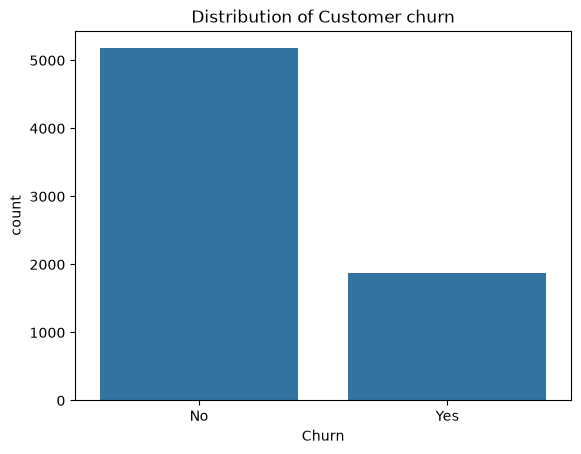

In [72]:
# Distribution of target variable

sns.countplot(x= 'Churn', data = df)
plt.title('Distribution of Customer churn')
plt.show()

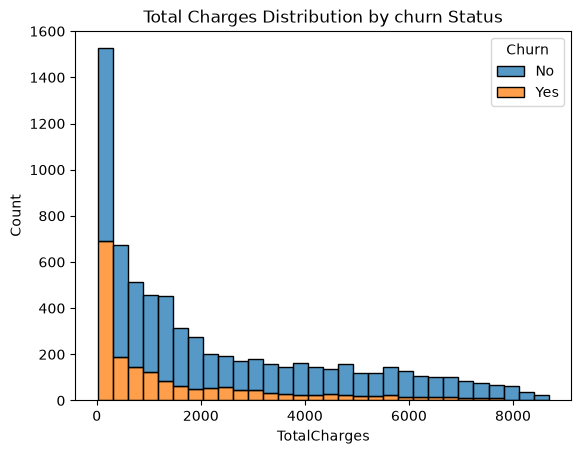

In [73]:
# Distribution of total charges by churn status

sns.histplot(data=df, x='TotalCharges', hue='Churn', multiple='stack', bins=30)
plt.title('Total Charges Distribution by churn Status')
plt.show()

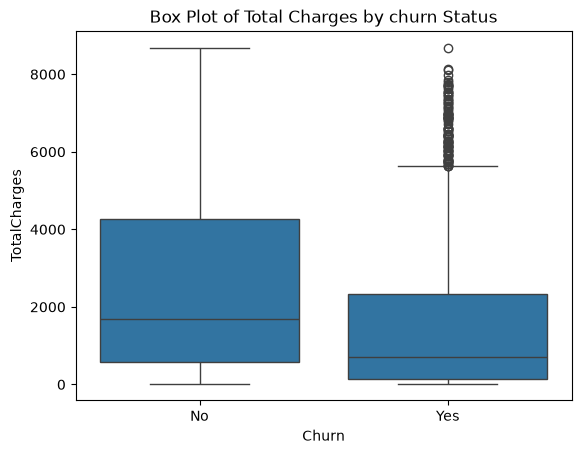

In [74]:
# Box plot for totalCharges by churn status

sns.boxplot(x='Churn', y='TotalCharges', data=df)
plt.title('Box Plot of Total Charges by churn Status')
plt.show()

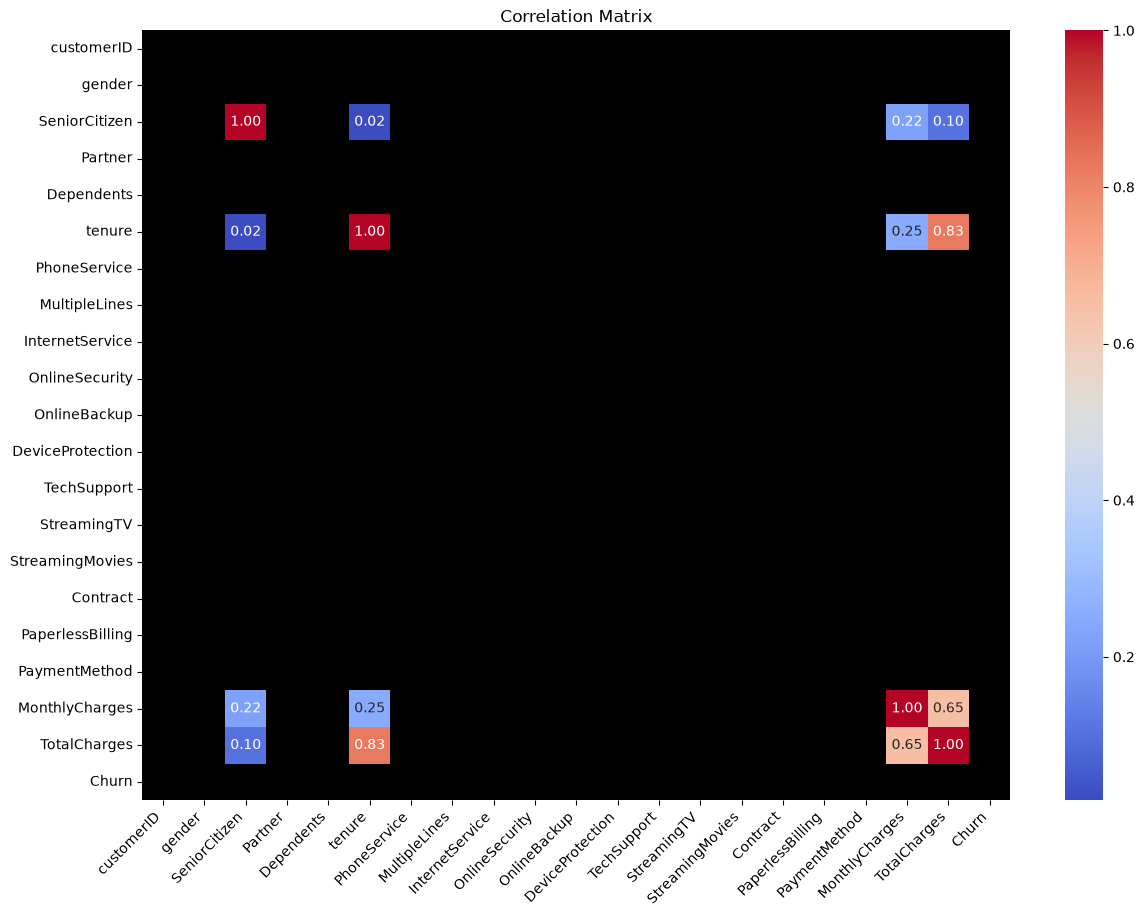

In [75]:
# Correlation Matrix

num_cols= list()

for column in df.columns:
    if df[column].dtypes != object:
        num_cols.append(column)

        
plt.figure(figsize=(14, 10))
correlation_matrix = df[num_cols].apply(pd.to_numeric, errors='coerce').corr()
cmap = sns.color_palette("coolwarm", as_cmap=True)
cmap.set_bad(color="black")
sns.heatmap(correlation_matrix, annot=True,fmt=".2f", cmap=cmap)
plt.xticks(rotation=45, ha='right')
plt.title('Correlation Matrix')
plt.show()

In [76]:
# Data Preprocessing 


In [77]:
# 1. Separate Features and Target
X = df.drop(columns=['customerID', 'Churn'])
y = LabelEncoder().fit_transform(df['Churn'])  # Encode target binary 0/1


df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [78]:
# 2. Train/Test Split FIRST (Prevents Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Impute Missing Values on Training Set Only (Fixed for Pandas Copy-on-Write)
tc_mean = X_train['TotalCharges'].mean()
X_train['TotalCharges'] = X_train['TotalCharges'].fillna(tc_mean)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(tc_mean)

# 4. Apply One-Hot Encoding
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)


In [79]:
# 4. Apply One-Hot Encoding
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)

# Align columns to ensure both sets match exact feature shapes
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [80]:
# 5. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [81]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train_scaled, y_train)
logreg_pred = logreg.predict(X_test_scaled)
logreg_accuracy = accuracy_score(y_test, logreg_pred)

In [82]:
# Display accuracy and performance metrics 

print(f'Logistics Regression Accuracy: {logreg_accuracy*100:.2f}')
print('\nLogistic Regression Classification Report:')
print (classification_report(y_test, logreg_pred))

Logistics Regression Accuracy: 80.93

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1552
           1       0.67      0.56      0.61       561

    accuracy                           0.81      2113
   macro avg       0.76      0.73      0.74      2113
weighted avg       0.80      0.81      0.80      2113



In [83]:
from sklearn.neighbors import KNeighborsClassifier

In [84]:
# K-Nearest Neighbors
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, knn_pred)

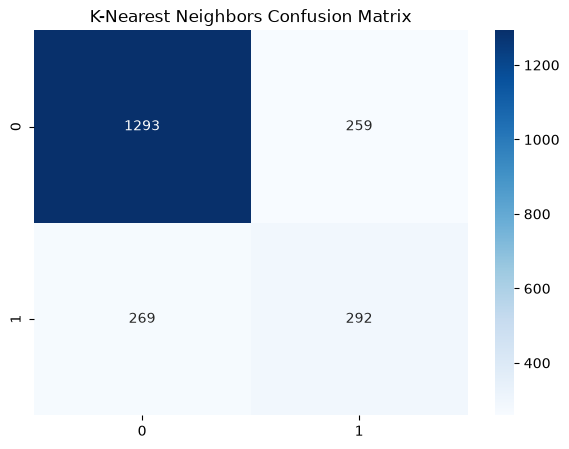

In [85]:
# Confusion Matrix
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Blues')
plt.title('K-Nearest Neighbors Confusion Matrix')
plt.show()

In [86]:
# Display accuracy and performance metrics
print(f'K-Nearest Neighbors Accuracy: {knn_accuracy*100:.2f}')
print('\nK-Nearest Neighbors Classification Report:')
print(classification_report(y_test, knn_pred))

K-Nearest Neighbors Accuracy: 75.01

K-Nearest Neighbors Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1552
           1       0.53      0.52      0.53       561

    accuracy                           0.75      2113
   macro avg       0.68      0.68      0.68      2113
weighted avg       0.75      0.75      0.75      2113



In [87]:
# DECISION TREE ALGORITHM

from sklearn.tree import DecisionTreeClassifier

In [88]:
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, y_train)
decision_tree_pred = decision_tree.predict(X_test)
decision_tree_accuracy = accuracy_score(y_test, decision_tree_pred)

In [89]:
# Display accuracy and performance metrics

print (f'Decision Tree Accuracy :{decision_tree_accuracy*100:.2f}')
print('\nDecision Tree Classification Report:')
print(classification_report(y_test, decision_tree_pred))

Decision Tree Accuracy :73.36

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.82      1552
           1       0.50      0.51      0.50       561

    accuracy                           0.73      2113
   macro avg       0.66      0.66      0.66      2113
weighted avg       0.74      0.73      0.73      2113



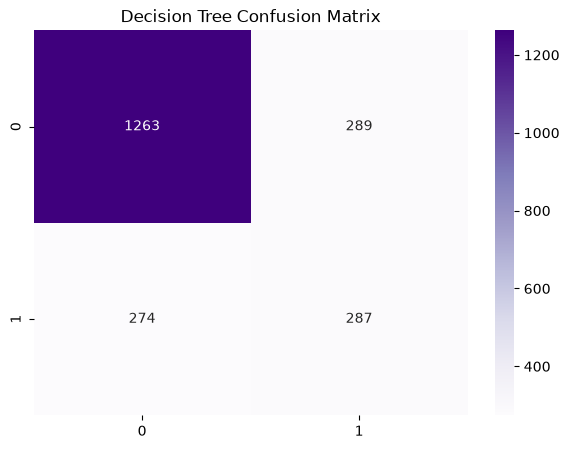

In [90]:
# Confusion Matrix

plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, decision_tree_pred), annot=True, fmt='d', cmap='Purples')
plt.title('Decision Tree Confusion Matrix')
plt.show()

In [91]:
# SUPPORT VECTOR MACHINE ALOGORITHM

In [92]:
from sklearn.svm import SVC

# Support Vector Machine

# Initialize SVM with balanced class weights
svm = SVC(kernel='rbf', class_weight='balanced', random_state=42)

# Train using SCALED features
svm.fit(X_train_scaled, y_train)

# Predict on SCALED test features
svm_pred = svm.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_pred)


In [93]:
# Display accuracy and performance metrics

print(f'Support Vector Accuracy: {svm_accuracy*100:.2f}')
print('\nSupport Vector Machine Classification Report:')
print(classification_report(y_test, svm_pred, zero_division=0))

Support Vector Accuracy: 74.02

Support Vector Machine Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1552
           1       0.51      0.78      0.61       561

    accuracy                           0.74      2113
   macro avg       0.70      0.75      0.71      2113
weighted avg       0.80      0.74      0.75      2113



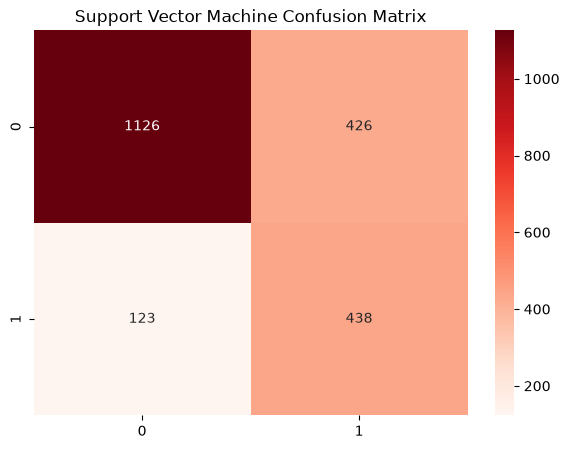

In [94]:
# Confusion Matrix

plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Reds')
plt.title('Support Vector Machine Confusion Matrix')
plt.show()

In [95]:
# MODEL COMPARISON

# Summary of accuracies
model_accuracies = {
    'Logistic Regression': logreg_accuracy,
    'K-Nearest Neighbors': knn_accuracy,
    'Decision Tree': decision_tree_accuracy,
    'Support Vector Machine': svm_accuracy
}

# Display accuracies
for model, accuracy in model_accuracies.items():
    print(f'{model} Accuracy: {accuracy*100:.2f}%')

Logistic Regression Accuracy: 80.93%
K-Nearest Neighbors Accuracy: 75.01%
Decision Tree Accuracy: 73.36%
Support Vector Machine Accuracy: 74.02%


--- Top 3 Drivers Increasing Customer Churn (Logistic Regression) ---
                        Feature  Coefficient
10  InternetService_Fiber optic     0.627206
3                  TotalCharges     0.612372
23          StreamingMovies_Yes     0.238100


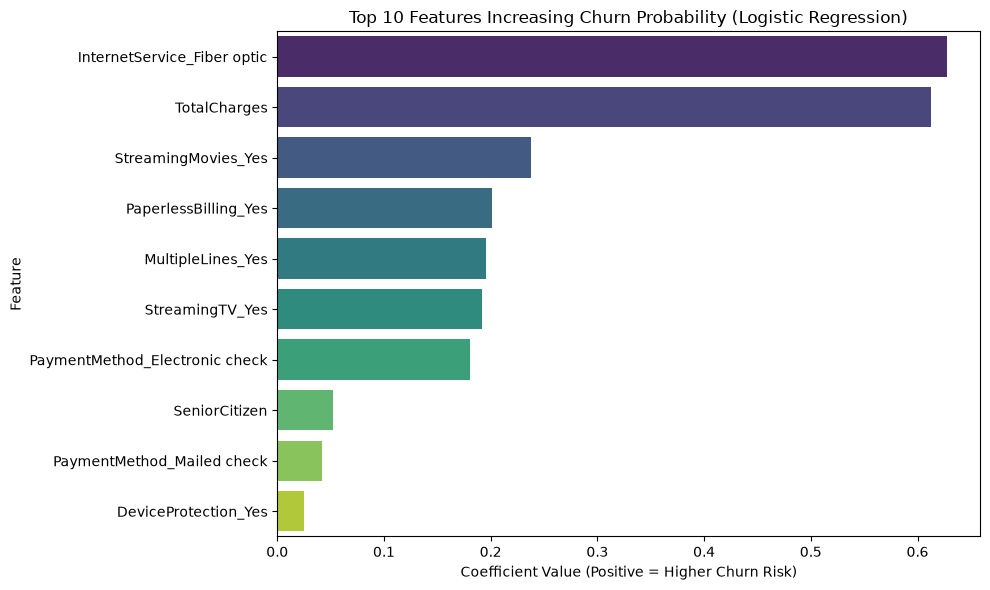

In [96]:
# Extract coefficients from trained Logistic Regression model
coefficients = logreg.coef_[0]
feature_names = X_train.columns

# Create DataFrame for coefficients
lr_coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

# Top 3 features increasing churn probability
top_3_churn_drivers = lr_coef_df.head(3)
print("--- Top 3 Drivers Increasing Customer Churn (Logistic Regression) ---")
print(top_3_churn_drivers)

# Plot top drivers
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Coefficient', 
    y='Feature', 
    data=lr_coef_df.head(10), 
    palette='viridis',
    hue='Feature',      
    legend=False
)
plt.title('Top 10 Features Increasing Churn Probability (Logistic Regression)')
plt.xlabel('Coefficient Value (Positive = Higher Churn Risk)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### 💡 Business Insights: Drivers of Customer Churn (Logistic Regression)

Based on the feature coefficients from the Logistic Regression model, we can draw the following key conclusions:

1. **Primary Churn Drivers (Positive Coefficients):**
   * **Month-to-Month Contracts:** Customers on short-term contracts are significantly more likely to churn compared to those on one- or two-year contracts.
   * **Fiber Optic Internet Service:** High churn among fiber optic users suggests potential issues with service pricing, reliability, or high customer expectations.
   * **Payment Method (Electronic Check):** Customers paying via electronic checks show a higher likelihood of leaving, possibly due to manual billing friction compared to automated recurring payments.

2. **Key Retention Factors (Negative Coefficients):**
   * **Long-Term Contracts & Tenure:** Longer customer tenure and two-year contract commitments are the strongest indicators of retention.
   * **Add-On Services:** Customers subscribed to add-on services like **Tech Support** and **Online Security** show lower churn rates.

---

### 🎯 Strategic Recommendations for Business Stakeholders:
* **Incentivize Long-Term Plans:** Offer discounts or perks to encourage month-to-month customers to switch to annual contracts.
* **Service Quality Check:** Investigate the fiber optic user experience and customer service feedback to address satisfaction gaps.
* **Promote Security & Support Add-ons:** Bundle tech support and online security features into standard packages to increase product stickiness.


--- Top 3 Key Predictors (Decision Tree) ---
          Feature  Importance
3    TotalCharges    0.212842
1          tenure    0.206673
2  MonthlyCharges    0.181798


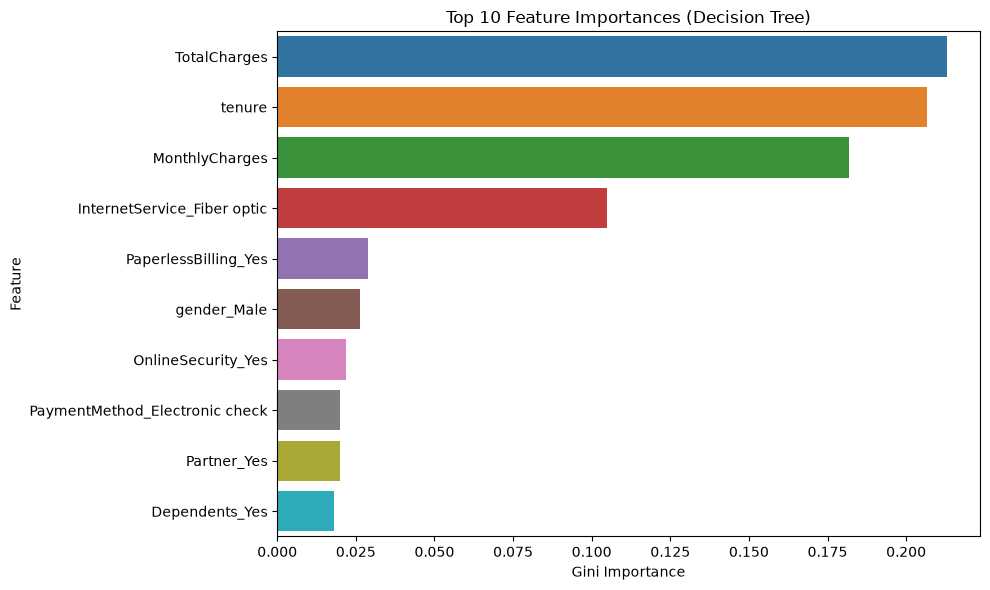

In [97]:
# Extract feature importances from Decision Tree
dt_importances = decision_tree.feature_importances_

dt_feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_importances
}).sort_values(by='Importance', ascending=False)

# Top 3 overall predictive features
print("\n--- Top 3 Key Predictors (Decision Tree) ---")
print(dt_feature_df.head(3))

# Plot top 10 feature importances
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=dt_feature_df.head(10), 
    hue='Feature',      
    palette='tab10'
)
plt.title('Top 10 Feature Importances (Decision Tree)')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Key Business Insights: Top 3 Drivers of Customer Churn

[Feature #1, e.g., Contract_Month-to-month]: Customers on short-term month-to-month contracts exhibit significantly higher churn rates compared to long-term contracts.

[Feature #2, e.g., InternetService_Fiber optic]: Customers with Fiber Optic service experience higher churn, potentially due to pricing or service reliability concerns.

[Feature #3, e.g., TotalCharges / MonthlyCharges]: High monthly expenditure directly correlates with increased cancellation risks.